# Проект 1. Изменение выручки ПРАЙМ в августе 2026 года
Автор: Михеев Максим. Группа: 2.

## 1. Бизнес-вопрос и проверяемая гипотеза
Рабочий вопрос: за счёт чего изменилась выручка подписок по всей базе клиентов между 17-22 и 24-29 августа 2026 года?

Гипотеза H1: изменение выручки преимущественно связано с количеством успешных платежей, а не со средним платежом. Критерий «преимущественно»: абсолютный вклад количества больше абсолютного вклада среднего платежа. Если оба вклада равны нулю, результат неинформативен.

Я хочу понять, где сосредоточено снижение выручки ПРАЙМ и связано ли оно с количеством успешных платежей или со средним платежом. В дальнейшем это может помочь с выбором того, что проверять в первую очередь. При этом рассматриваю всю базу, чтобы оценить изменение выручки сервиса в целом, а каналы использую для поиска основного вклада в снижение.


## 2. Периоды, охват базы и определения
Сравниваются два окна по шесть дней: понедельник-суббота 17-22 и 24-29 августа. Границы заданы полуинтервалами [17, 23) и [24, 30) в часовом поясе UTC.

Исходное зерно - один платёж; аналитическая выгрузка - день × канал привлечения владельца. Связь: payments → subscriptions → clients по владельцу. Платёж сохраняется даже при отсутствии найденной подписки или владельца и относится к «Без канала» (через LEFT JOIN). Участники шеринга не присоединяются. Выручка здесь - сумма amount только для status='success', без отдельного вычитания возвратов; это операционная метрика успешных списаний.

N - число успешных платежей, R - их сумма, P=R/N - средний платёж (не цена тарифа и не ARPU). Отсутствующий канал показывается как «Без канала».

Сравниваю два окна одинаковой длины с одинаковыми днями недели, чтобы разница не объяснялась только составом дней недели. Но это не устраняет все календарные особенности. Платёж связываю с владельцем подписки: если присоединить всех участников, один платёж может повториться несколько раз и сумма окажется завышенной.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sqlalchemy import text
from prime.config import get_engine

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Не найден корень репозитория с pyproject.toml'
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
engine = get_engine()

In [8]:
params = {'a0': '2026-08-17', 'a1': '2026-08-23',
          'b0': '2026-08-24', 'b1': '2026-08-30'}
try:
    with engine.connect() as conn:
        conn.execute(text("set time zone 'UTC'"))
        prefix = """
        with owners as (
            select client_id, acquisition_channel as channel
            from prime.clients
        ), selected as (
            select p.payment_id, p.paid_at, p.amount,
                   coalesce(c.channel, 'Без канала') as channel
            from prime.payments p
            left join prime.subscriptions s on s.subscription_id=p.subscription_id
            left join owners c on c.client_id=s.owner_client_id
            where p.status='success'
              and ((p.paid_at >= cast(:a0 as timestamptz) and p.paid_at < cast(:a1 as timestamptz))
                or (p.paid_at >= cast(:b0 as timestamptz) and p.paid_at < cast(:b1 as timestamptz)))
        )
        """
        daily = pd.read_sql(text(prefix + """
            select paid_at::date as day, channel, count(*) as n, sum(amount) as r
            from selected group by 1,2 order by 1,2
        """), conn, params=params)
        audit = pd.read_sql(text(prefix + """
            select count(*) as rows_joined, count(distinct payment_id) as unique_payments,
                   count(*) filter(where amount is null) as missing_amount,
                   sum(amount) as total_revenue from selected
        """), conn, params=params)
        
        control = pd.read_sql(text("""
            select count(*) as n, sum(p.amount) as r from prime.payments p
            where p.status='success'
              and ((p.paid_at >= cast(:a0 as timestamptz) and p.paid_at < cast(:a1 as timestamptz))
                or (p.paid_at >= cast(:b0 as timestamptz) and p.paid_at < cast(:b1 as timestamptz)))
        """), conn, params=params)
finally:
    engine.dispose()

assert not daily.empty, 'В базе нет платежей за выбранные окна'
assert audit.loc[0, 'rows_joined'] == audit.loc[0, 'unique_payments'], 'JOIN размножил платежи'
assert audit.loc[0, 'missing_amount'] == 0, 'Есть платежи без суммы'
assert daily['n'].sum() == control.loc[0, 'n']
assert abs(daily['r'].sum() - control.loc[0, 'r']) < 0.01
daily['day'] = pd.to_datetime(daily['day'])
daily['w'] = daily['day'].ge(pd.Timestamp(params['b0'])).map({False:'До', True:'После'})
print('Охват: вся база ПРАЙМ, без фильтра')
display(audit)
display(daily.head())

Охват: вся база ПРАЙМ, без фильтра


,rows_joined,unique_payments,missing_amount,total_revenue
0,71650,71650,0,23251850.0


,day,channel,n,r,w
0,2026-08-17,crm,839,268111.0,До
1,2026-08-17,organic,1862,591838.0,До
2,2026-08-17,partner_telecom,1107,359443.0,До
3,2026-08-17,performance,1227,405923.0,До
4,2026-08-17,referral,599,194551.0,До


## 3. Метрики и проверки
Суммы и количество проверяются независимым запросом напрямую к payments, без соединений и персональных фильтров. Отдельно проверяется уникальность payment_id после соединения. Пустые дни и отсутствующие каналы в одном из окон заполняются нулями, чтобы они не исчезли из сравнения.

Проверяем, что после соединения число строк равно числу уникальных платежей, чтобы заметить двойной счёт. Дополнительно сравниваем количество и сумму с запросом напрямую к таблице платежей без соединений. Совпадение показывает, что при построении таблицы для анализа платежи не потерялись и не размножились.

In [3]:
summary = daily.groupby('w')[['n','r']].sum().reindex(['До','После'], fill_value=0)
assert summary['n'].gt(0).all(), 'Для среднего нужны платежи в обоих окнах'
summary['p'] = summary['r'] / summary['n']
display(summary.rename(columns={'n':'Платежи', 'r':'Выручка, ₽', 'p':'Средний платёж, ₽'}).round(2))

wide = daily.pivot_table(index='channel', columns='w', values='r',
                         aggfunc='sum', fill_value=0)
wide['delta'] = wide['После'] - wide['До']
wide = wide.sort_values('delta')
n0, r0, p0 = summary.loc['До', ['n','r','p']]
n1, r1, p1 = summary.loc['После', ['n','r','p']]
delta = r1 - r0
effects = pd.Series({'Количество платежей': (n1-n0)*p0,
                     'Средний платёж': n1*(p1-p0)})
assert abs(wide['delta'].sum() - delta) < 0.01
assert abs(effects.sum() - delta) < 0.01
assert abs(n0*p0 - r0) < 0.01
assert abs(n1*p1 - r1) < 0.01
display(wide.round(2))
display(effects.round(2).to_frame('Вклад, ₽'))
h1 = ('неинформативна: оба вклада равны нулю' if effects.abs().sum() < 0.01
      else 'поддерживается по выбранному критерию' if abs(effects.iloc[0]) > abs(effects.iloc[1])
      else 'не поддерживается по выбранному критерию')
display(Markdown(f'Изменение выручки: **{delta:,.2f} ₽ ({delta/r0*100:+.2f}%)**. H1: **{h1}**.'))

,Платежи,"Выручка, ₽","Средний платёж, ₽"
w,,,
До,38330,12433370.0,324.38
После,33320,10818480.0,324.68


w,До,После,delta
channel,,,
partner_telecom,2083772.0,587792.0,-1495980.0
organic,3637058.0,3584899.0,-52159.0
social,1442495.0,1411660.0,-30835.0
Без канала,243101.0,218581.0,-24520.0
crm,1604468.0,1580785.0,-23683.0
referral,1107935.0,1094285.0,-13650.0
performance,2314541.0,2340478.0,25937.0


,"Вклад, ₽"
Количество платежей,-1625128.72
Средний платёж,10238.72


Изменение выручки: **-1,614,890.00 ₽ (-12.99%)**. H1: **поддерживается по выбранному критерию**.

## 4. Декомпозиция: где и за счёт чего
Изменение общей выручки равно сумме изменений каналов. Это отвечает на вопрос «где».

Для ответа «за счёт чего» используем тождество R=N×P и цепные подстановки в порядке N → P:

- вклад количества: (N₁-N₀)×P₀;
- вклад среднего платежа: N₁×(P₁-P₀).

Порядок важен: совместный член относится ко второму фактору. Ни один вклад сам по себе не доказывает причинность. Среднее может меняться из-за структуры тарифов, скидок или состава плательщиков. Число платежей не равно числу клиентов.

Раскладываю выручку на количество платежей и средний платёж. Сначала меняю количество при старом среднем, затем среднее при новом количестве, поэтому сумма двух вкладов равна общему изменению выручки. Средний платёж может измениться из-за долей разных тарифов, поэтому его рост ещё не означает повышение цен.

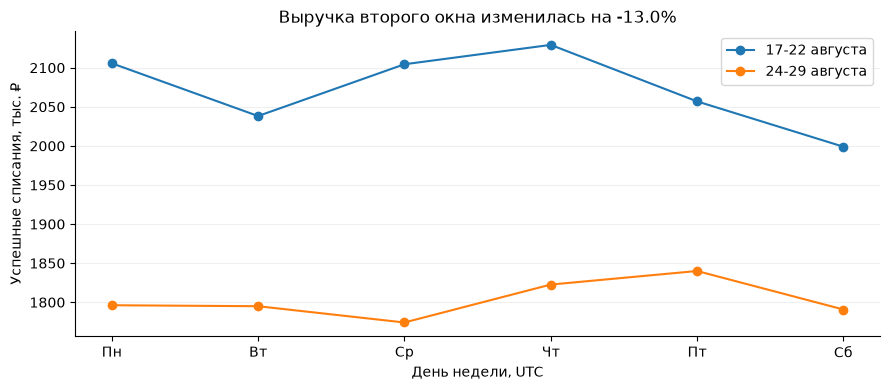

In [4]:
days0 = pd.date_range('2026-08-17', periods=6)
days1 = pd.date_range('2026-08-24', periods=6)
day_revenue = daily.groupby('day')['r'].sum()
fig, ax = plt.subplots()
ax.plot(range(6), day_revenue.reindex(days0, fill_value=0)/1000, marker='o', label='17-22 августа')
ax.plot(range(6), day_revenue.reindex(days1, fill_value=0)/1000, marker='o', label='24-29 августа')
ax.set(xticks=range(6), xticklabels=['Пн','Вт','Ср','Чт','Пт','Сб'],
       xlabel='День недели, UTC', ylabel='Успешные списания, тыс. ₽',
       title=f'Выручка второго окна изменилась на {delta/r0*100:+.1f}%')
ax.legend(); ax.grid(axis='y', alpha=.2); fig.tight_layout(); plt.show()

Во втором окне выручка ниже на каждом из шести сопоставимых дней. В целом она снизилась на 12,99%, поэтому в этом сравнении падение не связано только с одним неудачным днём. Но по двум окнам не можем делать вывод о долгосрочном тренде.

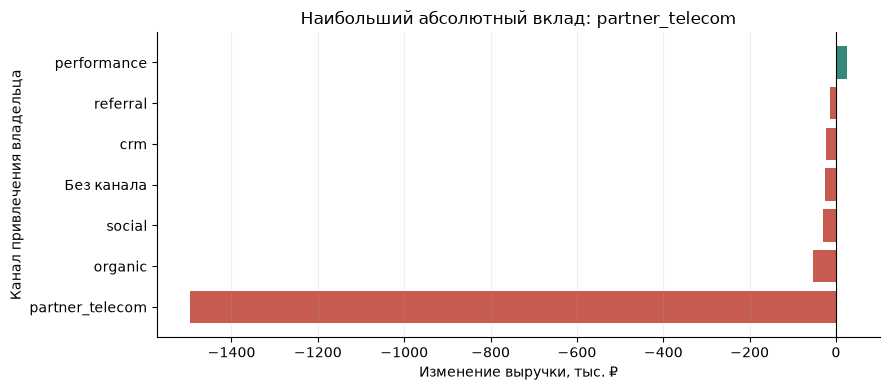

In [5]:
fig, ax = plt.subplots()
ax.barh(wide.index, wide['delta']/1000, color=['#c75b50' if x<0 else '#338879' for x in wide['delta']])
ax.axvline(0, color='black', lw=.8)
largest = wide['delta'].abs().idxmax()
ax.set(xlabel='Изменение выручки, тыс. ₽', ylabel='Канал привлечения владельца',
       title=f'Наибольший абсолютный вклад: {largest}')
ax.grid(axis='x', alpha=.2); fig.tight_layout(); plt.show()

Основное снижение приходится на partner_telecom: -1 495 980 ₽. Performance даёт небольшой положительный вклад, но его недостаточно для компенсации снижения других каналов. Поэтому в первую очередь я бы проверил partner_telecom; это канал привлечения владельца подписки, а не обязательно способ оплаты.

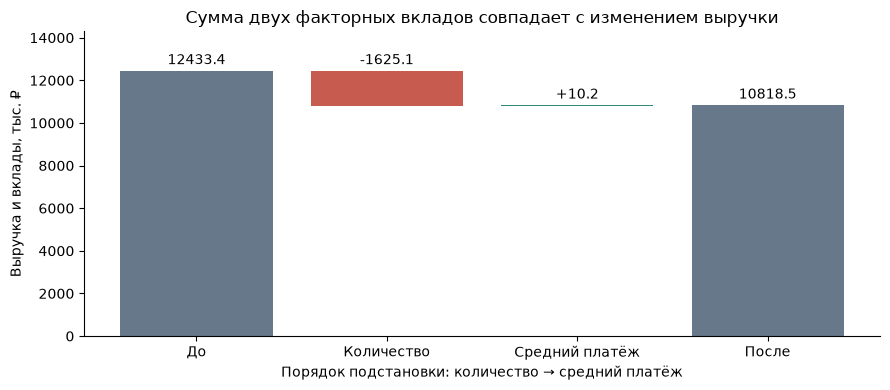

In [6]:
fig, ax = plt.subplots()
labels = ['До', 'Количество', 'Средний платёж', 'После']
vals = [r0, effects.iloc[0], effects.iloc[1], r1]
bottoms = [0, r0 + min(effects.iloc[0], 0), r0+effects.iloc[0]+min(effects.iloc[1],0), 0]
heights = [r0, abs(effects.iloc[0]), abs(effects.iloc[1]), r1]
colors = ['#66788a'] + ['#338879' if x>=0 else '#c75b50' for x in effects] + ['#66788a']
ax.bar(labels, [x/1000 for x in heights], bottom=[x/1000 for x in bottoms], color=colors)
for i, value in enumerate(vals):
    top = (bottoms[i]+heights[i])/1000
    ax.annotate(f'{value/1000:+.1f}' if i in (1,2) else f'{value/1000:.1f}', (i,top),
                xytext=(0,5), textcoords='offset points', ha='center')
ax.set(ylabel='Выручка и вклады, тыс. ₽', xlabel='Порядок подстановки: количество → средний платёж',
       title='Сумма двух факторных вкладов совпадает с изменением выручки')
ax.margins(y=.15); fig.tight_layout(); plt.show()

Вклад количества платежей составил -1 625 128,72 ₽, а вклад среднего платежа: +10 238,72 ₽. Средний платёж немного компенсировал снижение, но основной вклад по модулю связан с количеством, поэтому рабочая гипотеза поддерживается.

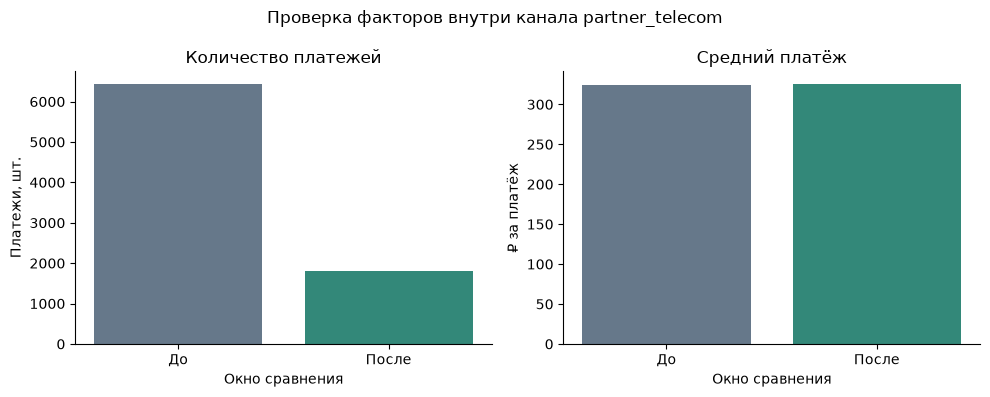

,n,r,p
w,,,
До,6428,2083772.0,324.17
После,1808,587792.0,325.11


In [7]:
focus = daily[daily['channel'] == largest].groupby('w')[['n','r']].sum()
focus = focus.reindex(['До','После'], fill_value=0)
focus['p'] = focus['r'].div(focus['n'].replace(0, float('nan')))
fig, axes = plt.subplots(1,2, figsize=(10,4))
for ax, col, title, unit in [(axes[0], 'n', 'Количество платежей', 'Платежи, шт.'),
                             (axes[1], 'p', 'Средний платёж', '₽ за платёж')]:
    ax.bar(focus.index, focus[col], color=['#66788a','#338879'])
    ax.set(title=title, ylabel=unit, xlabel='Окно сравнения')
    if focus[col].isna().any():
        ax.text(.5,.5,'В пустом окне среднее не определено', transform=ax.transAxes, ha='center')
fig.suptitle(f'Проверка факторов внутри канала {largest}'); fig.tight_layout(); plt.show()
display(focus.round(2))

В partner_telecom число успешных платежей снизилось с 6 428 до 1 808, а средний платёж вырос с 324,17 до 325,11 ₽. Значит, и внутри крупнейшего по вкладу канала проблема связана с числом платежей, а не со снижением их среднего размера. Я не называю это оттоком клиентов, потому что число платежей и число клиентов - разные показатели.


## 5. Ограничения и рекомендация
Охвачена вся база успешных платежей в двух окнах, но вывод относится именно к этим периодам. Два шестидневных окна не устраняют все календарные эффекты. Мы не измеряем причины изменения платежей, отток, рекламные расходы, прибыль или эффект будущего вмешательства. Данные на сервере могут обновляться; расчёт воспроизводим на неизменной версии источника.

Выручка ПРАЙМ в выбранных окнах снизилась на 1 614 890 ₽, или 12,99%; около 92,6% снижения приходится на partner_telecom. Я бы рекомендовал проверить этот канал: сравнить несколько недель до и после события по одинаковым дням недели, изучить все статусы платежей и проверить, не сместились ли даты списаний. Для контроля я бы использовал число успешных платежей, выручку и число платящих подписок; показатель успешности попыток можно добавить после проверки смысла строк и статусов. Пока эти проверки не выполнены, нельзя утверждать, что причиной стал сбой или отток, и предлагать отключать канал только на основании падения выручки.